In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
meter = pd.read_csv("meter_readings.csv")
customers = pd.read_csv("customers.csv")
weather = pd.read_csv("weather.csv")
calendar = pd.read_csv("calendar.csv")
tariff = pd.read_csv("tariff.csv")

datasets = {
    "Meter Readings": meter,
    "Customers": customers,
    "Weather": weather,
    "Calendar": calendar,
    "Tariff": tariff
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]:,} rows, {data.shape[1]} columns")

display(meter.head())

Meter Readings: 36,015 rows, 3 columns
Customers: 25 rows, 4 columns
Weather: 1,440 rows, 4 columns
Calendar: 1,440 rows, 4 columns
Tariff: 4,320 rows, 4 columns


,timestamp,customer,consumption
0,2025-01-01 00:00:00,C001,1.743
1,2025-01-01 00:00:00,C002,4.090
2,2025-01-01 00:00:00,C003,7.035
3,2025-01-01 00:00:00,C004,1.871
4,2025-01-01 00:00:00,C005,3.922


In [3]:
for name, data in datasets.items():
    print(f"\n--- {name} ---")
    display(data.head(3))
    print(data.dtypes)
    print("Missing values:")
    print(data.isnull().sum())
    print("Exact duplicate rows:", data.duplicated().sum())

print("\nNegative consumption readings:",
      (meter["consumption"] < 0).sum())

print("\nCustomer segment labels:")
print(customers["segment"].value_counts(dropna=False))


--- Meter Readings ---


,timestamp,customer,consumption
0,2025-01-01 00:00:00,C001,1.743
1,2025-01-01 00:00:00,C002,4.090
2,2025-01-01 00:00:00,C003,7.035


timestamp       object
customer        object
consumption    float64
dtype: object
Missing values:
timestamp       0
customer        0
consumption    35
dtype: int64
Exact duplicate rows: 15

--- Customers ---


,customer,segment,area,connection_type
0,C001,residential,North,Single-phase
1,C002,Commercial,South,Single-phase
2,C003,Industrial,East,Three-phase


customer           object
segment            object
area               object
connection_type    object
dtype: object
Missing values:
customer           0
segment            0
area               0
connection_type    0
dtype: int64
Exact duplicate rows: 0

--- Weather ---


...

timestamp       object
temperature    float64
humidity       float64
rain           float64
dtype: object
Missing values:
timestamp       0
temperature    12
humidity       10
rain            0
dtype: int64
Exact duplicate rows: 0

--- Calendar ---


,timestamp,weekday,holiday,season
0,2025-01-01 00:00:00,Wednesday,1,Winter
1,2025-01-01 01:00:00,Wednesday,1,Winter
2,2025-01-01 02:00:00,Wednesday,1,Winter


timestamp    object
weekday      object
holiday       int64
season       object
dtype: object
Missing values:
timestamp    0
weekday      0
holiday      0
season       0
dtype: int64
Exact duplicate rows: 0

--- Tariff ---


,timestamp,tariff_category,peak_period,tariff_rate_band
0,2025-01-01 00:00:00,Residential,Off-Peak,Standard
1,2025-01-01 00:00:00,Commercial,Off-Peak,Standard
2,2025-01-01 00:00:00,Industrial,Off-Peak,Standard


timestamp           object
tariff_category     object
peak_period         object
tariff_rate_band    object
dtype: object
Missing values:
timestamp           0
tariff_category     0
peak_period         0
tariff_rate_band    0
dtype: int64
Exact duplicate rows: 0

Negative consumption readings: 5

Customer segment labels:
segment
Commercial     8
Industrial     8
Residential    8
residential    1
Name: count, dtype: int64


In [4]:
# Make working copies
m = meter.copy()
c = customers.copy()
w = weather.copy()
cal = calendar.copy()
t = tariff.copy()

# Standardize date and time
for data in [m, w, cal, t]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], errors="coerce"
    )

# Remove rows with invalid timestamps
m = m.dropna(subset=["timestamp"])
w = w.dropna(subset=["timestamp"])
cal = cal.dropna(subset=["timestamp"])
t = t.dropna(subset=["timestamp"])

# Standardize customer and segment fields
for data in [m, c]:
    data["customer"] = data["customer"].astype(str).str.strip()

c["segment"] = c["segment"].astype("string").str.strip().str.title()
c["area"] = c["area"].astype("string").str.strip().str.title()
c["connection_type"] = (
    c["connection_type"].astype("string").str.strip().str.title()
)

# Remove exact duplicate records
m = m.drop_duplicates()
c = c.drop_duplicates()
w = w.drop_duplicates(subset=["timestamp"], keep="first")
cal = cal.drop_duplicates(subset=["timestamp"], keep="first")
t = t.drop_duplicates(
    subset=["timestamp", "tariff_category"], keep="first"
)

# Convert consumption to numeric and treat negative values as invalid
m["consumption"] = pd.to_numeric(m["consumption"], errors="coerce")
m.loc[m["consumption"] < 0, "consumption"] = np.nan

# Impute missing consumption using customer median, then overall median
customer_medians = m.groupby("customer")["consumption"].transform("median")
m["consumption"] = m["consumption"].fillna(customer_medians)
m["consumption"] = m["consumption"].fillna(m["consumption"].median())

# Fill weather gaps using time interpolation, then median as fallback
w = w.sort_values("timestamp").set_index("timestamp")
for col in ["temperature", "humidity", "rain"]:
    w[col] = pd.to_numeric(w[col], errors="coerce")
    w[col] = w[col].interpolate(method="time").ffill().bfill()
    w[col] = w[col].fillna(w[col].median())
w = w.reset_index()

# Standardize tariff fields
t["tariff_category"] = (
    t["tariff_category"].astype("string").str.strip().str.title()
)

# Merge data
df = m.merge(c, on="customer", how="left", validate="many_to_one")
df = df.merge(w, on="timestamp", how="left", validate="many_to_one")
df = df.merge(cal, on="timestamp", how="left", validate="many_to_one")
df = df.merge(
    t,
    left_on=["timestamp", "segment"],
    right_on=["timestamp", "tariff_category"],
    how="left",
    validate="many_to_one"
)

print("Cleaned and merged dataset:", df.shape)
display(df.head())

Cleaned and merged dataset: (36000, 15)


,timestamp,customer,consumption,segment,area,connection_type,temperature,humidity,rain,weekday,holiday,season,tariff_category,peak_period,tariff_rate_band
0,2025-01-01,C001,1.743,Residential,North,Single-Phase,21.8,73.3,10.71,Wednesday,1,Winter,Residential,Off-Peak,Standard
1,2025-01-01,C002,4.090,Commercial,South,Single-Phase,21.8,73.3,10.71,Wednesday,1,Winter,Commercial,Off-Peak,Standard
2,2025-01-01,C003,7.035,Industrial,East,Three-Phase,21.8,73.3,10.71,Wednesday,1,Winter,Industrial,Off-Peak,Standard
3,2025-01-01,C004,1.871,Residential,West,Single-Phase,21.8,73.3,10.71,Wednesday,1,Winter,Residential,Off-Peak,Standard
4,2025-01-01,C005,3.922,Commercial,Central,Single-Phase,21.8,73.3,10.71,Wednesday,1,Winter,Commercial,Off-Peak,Standard


In [5]:
df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.day
df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df["is_holiday"] = pd.to_numeric(
    df["holiday"], errors="coerce"
).fillna(0).astype(int)

df["is_peak_hour"] = df["peak_period"].eq("Peak").astype(int)

print("Engineered features:")
display(df[[
    "timestamp", "hour", "day_of_week", "is_weekend",
    "temperature", "segment", "area", "peak_period", "consumption"
]].head())

Engineered features:


,timestamp,hour,day_of_week,is_weekend,temperature,segment,area,peak_period,consumption
0,2025-01-01,0,2,0,21.8,Residential,North,Off-Peak,1.743
1,2025-01-01,0,2,0,21.8,Commercial,South,Off-Peak,4.090
2,2025-01-01,0,2,0,21.8,Industrial,East,Off-Peak,7.035
3,2025-01-01,0,2,0,21.8,Residential,West,Off-Peak,1.871
4,2025-01-01,0,2,0,21.8,Commercial,Central,Off-Peak,3.922


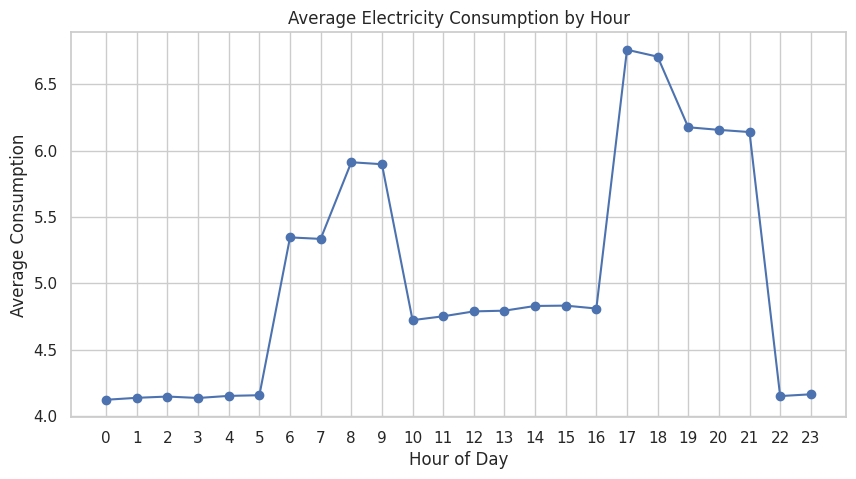

Peak hour: 17
Highest average consumption: 6.759


In [6]:
hourly = df.groupby("hour")["consumption"].mean()

plt.figure(figsize=(10, 5))
hourly.plot(marker="o")
plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption")
plt.xticks(range(24))
plt.show()

print("Peak hour:", hourly.idxmax())
print("Highest average consumption:", round(hourly.max(), 3))

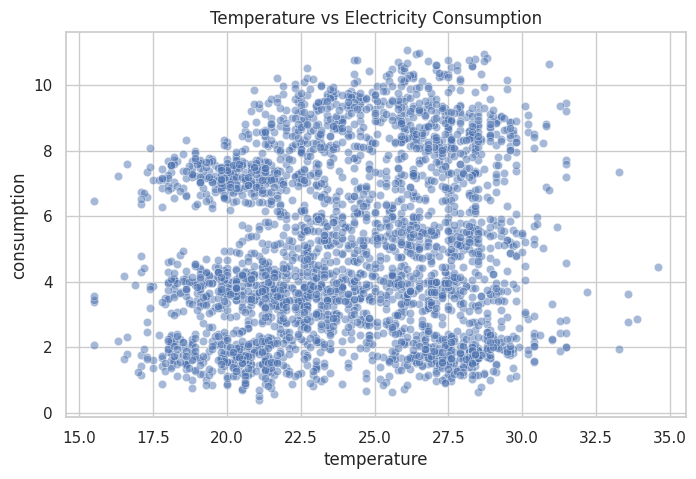

Temperature-consumption correlation: 0.135


In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(min(3000, len(df)), random_state=42),
    x="temperature", y="consumption", alpha=0.5
)
plt.title("Temperature vs Electricity Consumption")
plt.show()

print("Temperature-consumption correlation:",
      round(df["temperature"].corr(df["consumption"]), 3))

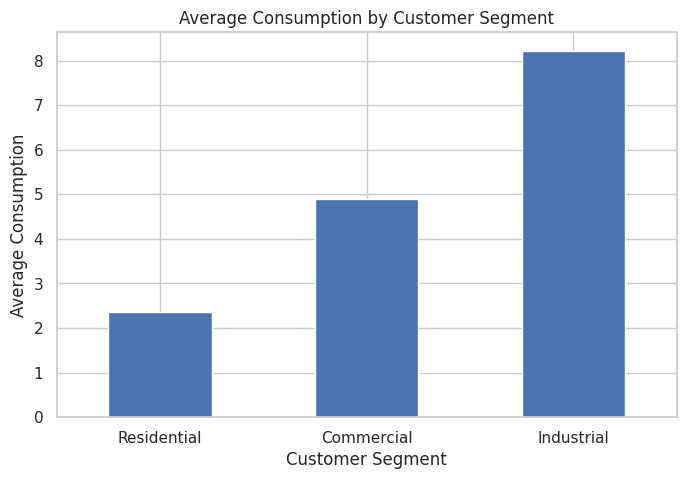

,Average Consumption
segment,
Residential,2.353942
Commercial,4.899380
Industrial,8.224209


In [8]:
segment_demand = df.groupby("segment")["consumption"].mean().sort_values()

segment_demand.plot(kind="bar", figsize=(8, 5))
plt.title("Average Consumption by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)
plt.show()

display(segment_demand.to_frame("Average Consumption"))

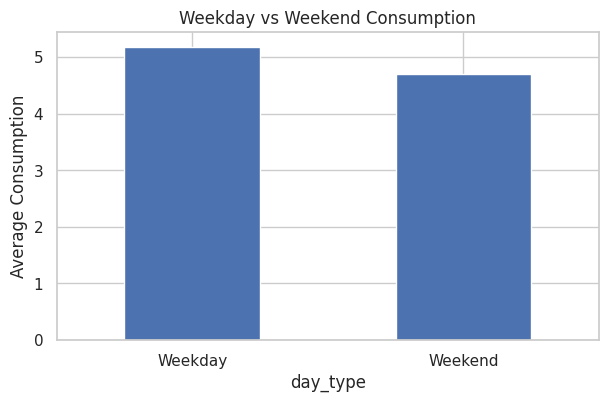

,Average Consumption
day_type,
Weekday,5.182393
Weekend,4.704420


In [9]:
df["day_type"] = np.where(df["is_weekend"] == 1, "Weekend", "Weekday")

weekend_demand = df.groupby("day_type")["consumption"].mean()

weekend_demand.plot(kind="bar", figsize=(7, 4))
plt.title("Weekday vs Weekend Consumption")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)
plt.show()

display(weekend_demand.to_frame("Average Consumption"))

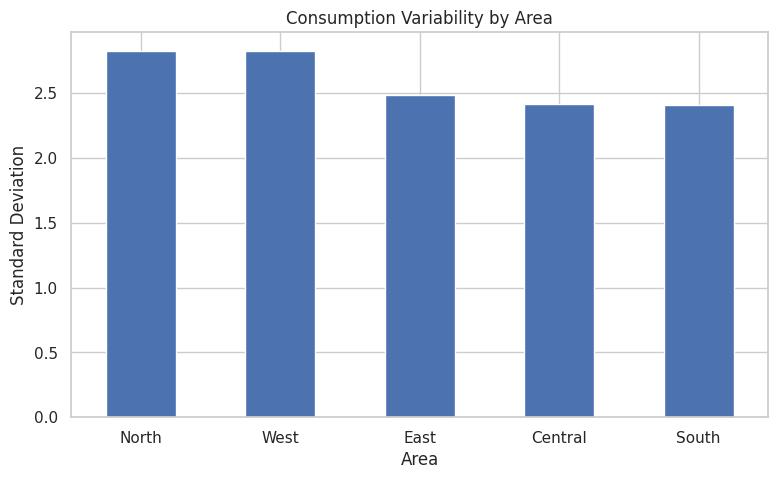

,mean,std,min,max
area,,,,
North,5.202658,2.829044,0.206,11.603
West,5.220296,2.826798,0.376,11.683
East,5.714844,2.489255,0.305,11.501
Central,4.552288,2.415138,0.145,11.477
South,4.544751,2.408825,0.314,12.016


Highest variability area: North


In [10]:
area_variability = (
    df.groupby("area")["consumption"]
      .agg(["mean", "std", "min", "max"])
      .sort_values("std", ascending=False)
)

area_variability["std"].plot(kind="bar", figsize=(9, 5))
plt.title("Consumption Variability by Area")
plt.xlabel("Area")
plt.ylabel("Standard Deviation")
plt.xticks(rotation=0)
plt.show()

display(area_variability)
print("Highest variability area:", area_variability["std"].idxmax())

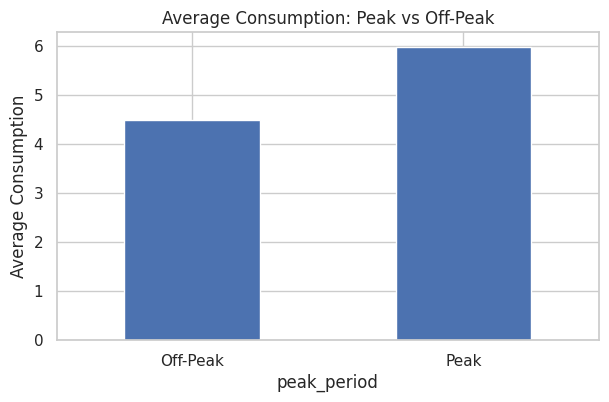

,mean,median,count
peak_period,,,
Off-Peak,4.488240,4.060,22500
Peak,5.978179,5.716,13500


In [11]:
tariff_analysis = df.groupby("peak_period")["consumption"].agg(
    ["mean", "median", "count"]
)

tariff_analysis["mean"].plot(kind="bar", figsize=(7, 4))
plt.title("Average Consumption: Peak vs Off-Peak")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)
plt.show()

display(tariff_analysis)

In [12]:
features = [
    "hour", "day_of_week", "month", "is_weekend", "is_holiday",
    "temperature", "humidity", "rain",
    "segment", "area", "connection_type", "peak_period"
]

target = "consumption"

model_df = df[features + [target]].dropna().copy()

X = model_df[features]
y = model_df[target]

numeric_features = [
    "hour", "day_of_week", "month", "is_weekend", "is_holiday",
    "temperature", "humidity", "rain"
]

categorical_features = [
    "segment", "area", "connection_type", "peak_period"
]

preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.4097
RMSE: 0.5154
R²:   0.9618


In [14]:
!pip install XlsxWriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.6 MB/s eta 0:00:00


In [17]:
import os

output_file = "Electricity_Consumption_Analysis.xlsx"

hourly_table = df.groupby("hour", as_index=False)["consumption"].mean()
hourly_table.columns = ["Hour", "Average Consumption"]

segment_table = df.groupby("segment", as_index=False)["consumption"].mean()
segment_table.columns = ["Segment", "Average Consumption"]

weekend_table = df.groupby("day_type", as_index=False)["consumption"].mean()
weekend_table.columns = ["Day Type", "Average Consumption"]

area_table = (
    df.groupby("area")["consumption"]
    .agg(["mean", "std"])
    .reset_index()
)

area_table = area_table.rename(columns={
    "area": "Area",
    "mean": "Average Consumption",
    "std": "Std Deviation"
})
tariff_table = df.groupby("peak_period", as_index=False)["consumption"].mean()
tariff_table.columns = ["Tariff Period", "Average Consumption"]


display(area_table)

summary = pd.DataFrame({
    "Metric": [
        "Cleaned records",
        "Peak demand hour",
        "Highest hourly average consumption",
        "Highest variability area",
        "MAE",
        "RMSE",
        "R-squared"
    ],
    "Result": [
        len(df),
        int(hourly.idxmax()),
        round(float(hourly.max()), 4),
        str(area_variability["std"].idxmax()),
        round(float(mae), 4),
        round(float(rmse), 4),
        round(float(r2), 4)
    ]
})

with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    df.to_excel(writer, sheet_name="Cleaned Data", index=False)
    hourly_table.to_excel(writer, sheet_name="Hourly Demand", index=False)
    segment_table.to_excel(writer, sheet_name="Segments", index=False)
    weekend_table.to_excel(writer, sheet_name="Weekend Analysis", index=False)
    area_table.to_excel(writer, sheet_name="Area Variability", index=False)
    tariff_table.to_excel(writer, sheet_name="Tariff Analysis", index=False)

    workbook = writer.book
    header_format = workbook.add_format({
        "bold": True, "bg_color": "#D9EAF7", "border": 1
    })

    for sheet_name, table in [
        ("Summary", summary),
        ("Hourly Demand", hourly_table),
        ("Segments", segment_table),
        ("Weekend Analysis", weekend_table),
        ("Area Variability", area_table),
        ("Tariff Analysis", tariff_table)
    ]:
        ws = writer.sheets[sheet_name]
        ws.freeze_panes(1, 0)
        ws.autofilter(0, 0, len(table), len(table.columns)-1)
        ws.set_row(0, None, header_format)
        ws.set_column(0, len(table.columns)-1, 24)

    # Add a chart to the hourly demand sheet
    ws = writer.sheets["Hourly Demand"]
    chart = workbook.add_chart({"type": "line"})
    chart.add_series({
        "name": "Average Consumption",
        "categories": ["Hourly Demand", 1, 0, len(hourly_table), 0],
        "values": ["Hourly Demand", 1, 1, len(hourly_table), 1]
    })
    chart.set_title({"name": "Hourly Electricity Demand"})
    chart.set_x_axis({"name": "Hour"})
    chart.set_y_axis({"name": "Average Consumption"})
    ws.insert_chart("D2", chart)

print("Excel workbook created:", output_file)

,Area,Average Consumption,Std Deviation
0,Central,4.552288,2.415138
1,East,5.714844,2.489255
2,North,5.202658,2.829044
3,South,4.544751,2.408825
4,West,5.220296,2.826798


Excel workbook created: Electricity_Consumption_Analysis.xlsx


In [18]:
from google.colab import files
files.download("Electricity_Consumption_Analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

chart_specs = [
    ("segment", "Segments", "Average Consumption by Segment"),
    ("day_type", "Weekend Analysis", "Weekday vs Weekend Consumption"),
    ("area", "Area Variability", "Average Consumption by Area"),
    ("peak_period", "Tariff Analysis", "Consumption by Peak Period")
]

chart_files = []

# Create chart images
for col, sheet_name, title in chart_specs:
    data = df.groupby(col)["consumption"].mean().dropna()

    plt.figure(figsize=(8, 5))
    data.plot(kind="bar")
    plt.title(title)
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Average Consumption")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    filename = f"{sheet_name.replace(' ', '_')}.png"
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.close()

    chart_files.append((col, sheet_name, filename))

# Create Excel workbook with matching sheet names
output_file = "Electricity_Consumption_Analysis_With_Charts.xlsx"

with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    for col, sheet_name, filename in [
        (col, sheet_name, filename)
        for col, sheet_name, filename in chart_files
    ]:
        table = df.groupby(col, as_index=False)["consumption"].mean()
        table.columns = [col.replace("_", " ").title(), "Average Consumption"]
        table.to_excel(writer, sheet_name=sheet_name, index=False)

        worksheet = writer.sheets[sheet_name]
        worksheet.insert_image("D2", filename)

print("Excel workbook created successfully!")
files.download(output_file)

Excel workbook created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

peak_period
Off-Peak    4.488240
Peak        5.978179
Name: consumption, dtype: float64


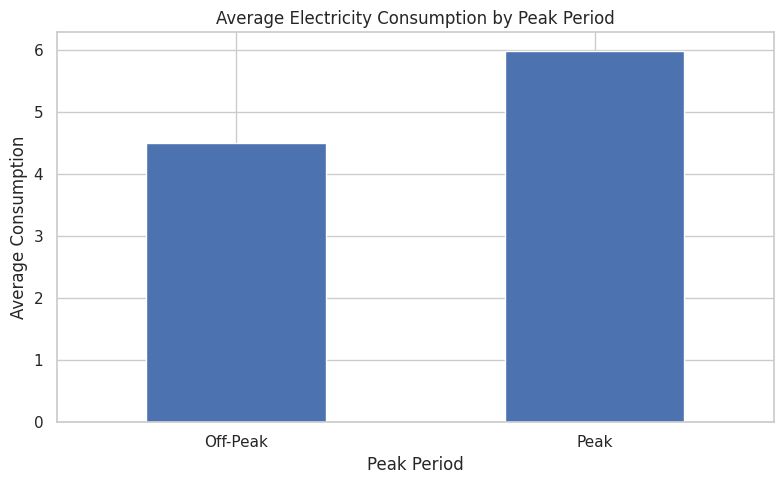

In [21]:
import matplotlib.pyplot as plt

tariff_data = df.groupby("peak_period")["consumption"].mean()

print(tariff_data)

tariff_data.plot(kind="bar", figsize=(8, 5))
plt.title("Average Electricity Consumption by Peak Period")
plt.xlabel("Peak Period")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()